In [1]:
#Jonathan Borowsky
#Grabe lab
#01/28/26

#rotamer calculation for collaboration with Rutter lab
#this notebook was used to develop the contents of x01_threonine_rotamers.py

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
from MDAnalysis.analysis.dssp import DSSP

#import compute_observable_on_trjs_x01_v3

In [30]:
#-------------------------------- load trajectory -------------------------------

whichprotein = "ucp1"
whichresidue = "thr"

toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/topol.top"
trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
u = mda.Universe(toppath, trjpath, topology_format='ITP')
protein_trj = u.select_atoms('protein')

n_frames = len(u.trajectory)
n_residues = len(u.select_atoms(f"resname {whichresidue.upper()}").residues)

/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


In [39]:
#-------------------------------- calculate hydrogen bonds -------------------------------

donornames = {"thr":"HG1", "ser":"HG1"}
acceptor_names = {"thr":"OG1", "ser":"OG"}

d_a_cutoff=3.3

h1 = HBA(universe=u, hydrogens_sel=f"resname {whichresidue.upper()} and name {donornames[whichresidue]}",
         acceptors_sel="resname TIP3 and name OH2", update_selections=False, d_a_cutoff=d_a_cutoff)
h1.run()

h2 = HBA(universe=u, hydrogens_sel="resname TIP3 and name H1 H2", 
         acceptors_sel=f"resname {whichresidue.upper()} and name {acceptor_names[whichresidue]}", update_selections=False, d_a_cutoff=d_a_cutoff)
h2.run()

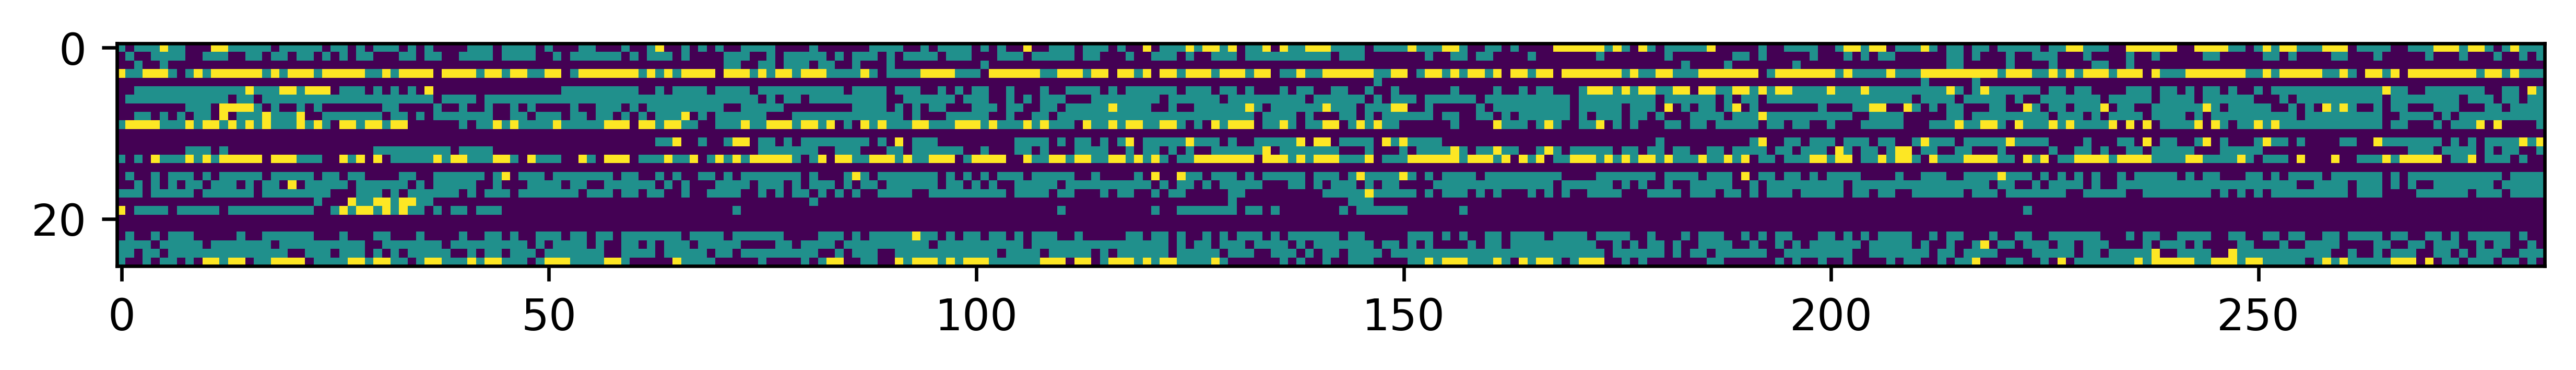

In [40]:
#-------------------------------- count hydrogen bonds by residue -------------------------------

#number of hydrogen bonds by frame and residue
hbonds_all = np.zeros((n_residues, n_frames)).astype(int)

query_resis = u.select_atoms(f"resname {whichresidue.upper()}").residues
#donor_inds = [[a.index for a in r.atoms if a.name == "HG1"][0] for r in query_resis]
acceptor_inds = [[a.index for a in r.atoms if a.name == acceptor_names[whichresidue]][0] for r in query_resis] #these are atom indices

for i, ai in enumerate(acceptor_inds):

    times_1 = h1.results.hbonds[np.where(h1.results.hbonds[:,1].astype(int)==ai),0].astype(int)
    for t1 in times_1:
        hbonds_all[i, t1] += 1 

    times_2 = h2.results.hbonds[np.where(h2.results.hbonds[:,3].astype(int)==ai),0].astype(int)
    for t2 in times_2:
        hbonds_all[i, t2] += 1 

plt.figure(figsize=(10,10), dpi=600)
plt.imshow(hbonds_all)
plt.show()

#print(np.sum(hbonds_all, axis = 1))


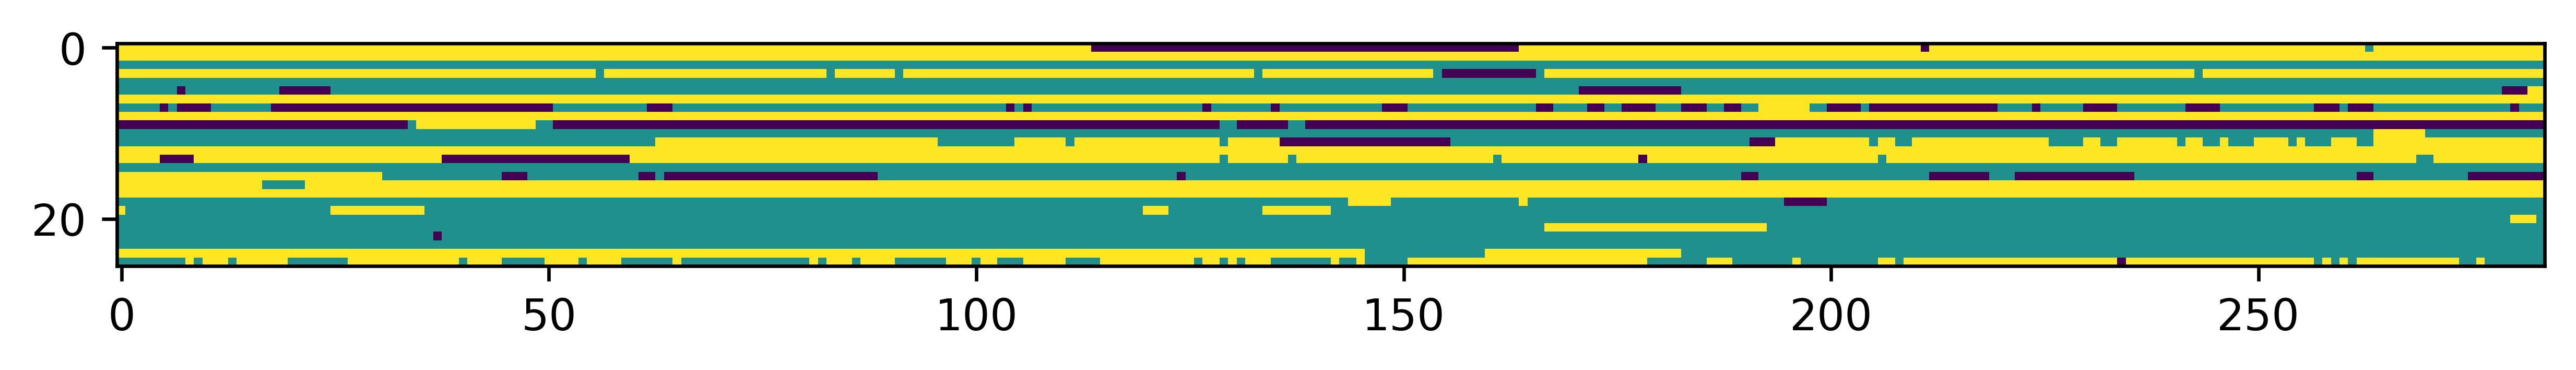

In [33]:
#-------------------------------- calculate dihedrals -------------------------------

#see https://userguide.mdanalysis.org/1.1.1/examples/analysis/structure/dihedrals.html
chi1_atoms = [res.chi1_selection() for res in query_resis]
chi1_dihedrals = dihedrals.Dihedral(chi1_atoms).run()
dihedral_angles = chi1_dihedrals.results.angles
x1_angles = dihedral_angles.transpose()

#-------------------------------- discretize trajectory -------------------------------
#mapping: 
#         a < -120 : 0
# -120 <= a <    0 : 1
#    0 <= a <  120 : 2
#  120 <= a         : 3

rotamer_bounds = [-120, 0, 120]
n_rotamers = len(rotamer_bounds)

rotamer_trj = np.digitize(x1_angles, rotamer_bounds) #this splits the rotamer centered on +-180 degrees into two bins
rotamer_trj = np.where(rotamer_trj == n_rotamers, 0, rotamer_trj).astype(int) #merge the bins for the rotamer at 180 degrees back together

#this is basically redundant with the discrete rotamer
plot_angles=False
if plot_angles:
    plt.figure(figsize=(10,10), dpi=600)
    plt.imshow(x1_angles, vmin=-180, vmax=180)
    plt.show()

plt.figure(figsize=(10,10), dpi=600)
plt.imshow(rotamer_trj)
plt.show()


In [34]:
#-------------------------------- calculate secondary structure for each frame -------------------------------

secstr = DSSP(u).run().results.dssp
secstr_num = np.where(secstr=='H', 1, 0)# + np.where(secstr=='E', 2, 0) #there are vanishingly few sheet assignments, which are all standalone misclassified loops

plot_all_ss = False
if plot_all_ss:
    print("".join([str(i) for i in secstr_num[0]]))
    plt.figure(figsize=(10,10), dpi=600)
    plt.imshow(secstr_num)
    plt.show()

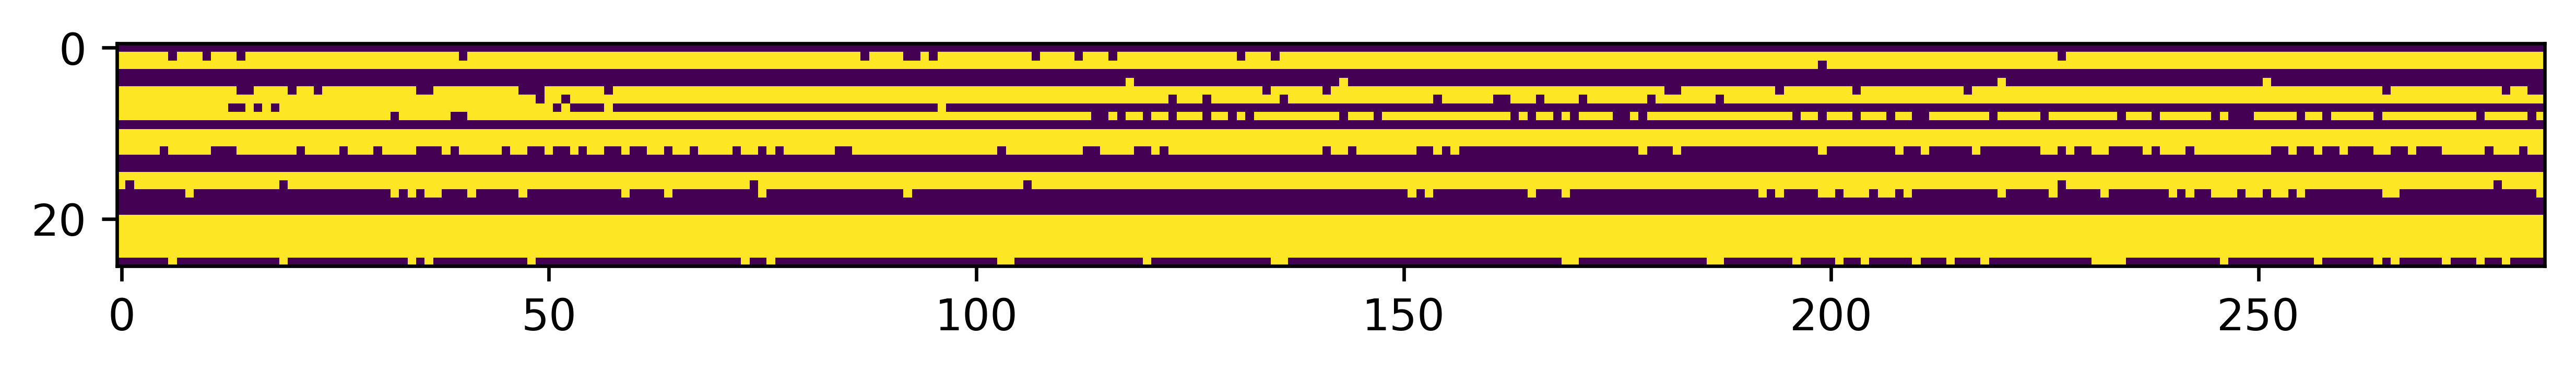

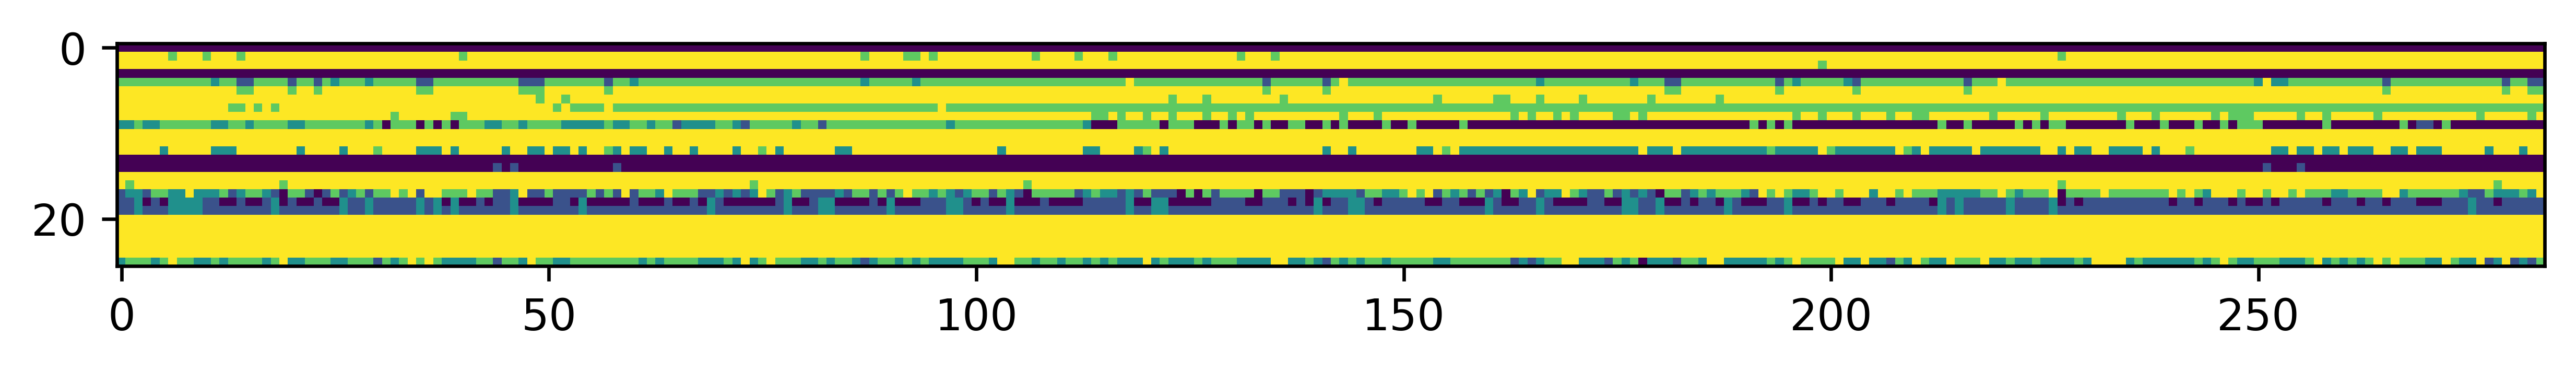

In [35]:
#-------------------------------- find threonines on helices long enough to support backbone H bonding -------------------------------
#0-indexed to match secondary structure
thr_indices = query_resis.resids-u.residues[0].resid

helix_counts = np.zeros((n_residues, n_frames))
helix_assignments = np.zeros((n_residues, n_frames)).astype(int)

for i, th in enumerate(thr_indices):
    #the first few residues don't have enough residues on the n side of them to form another helix turn, and would throw index out of bounds errors
    if th>=4: 
        #select each threonine and the four preceding residues, which include the carbonyl of interest
        support_resis = secstr_num[:,th-4:th] 
        support_helical_count = np.sum(support_resis, axis = 1)
        helix_assignments[i] = np.where(support_helical_count==4, 1, 0)
        helix_counts[i] = support_helical_count

plt.figure(figsize=(10,10), dpi=600)
plt.imshow(helix_assignments)
plt.show()
plt.figure(figsize=(10,10), dpi=600)
plt.imshow(helix_counts)
plt.show()

In [22]:
###########################################################################################################
#                                            CORRELATIONS
###########################################################################################################

In [41]:
helix_rotamer_hbonds = np.zeros((2,3,3))

for x,y,z in zip(helix_assignments.flatten(), rotamer_trj.flatten(), hbonds_all.flatten()):
        helix_rotamer_hbonds[x,y,z]+=1

#TODO: weight counts by number of transitions or by p(a)(1-p(a)) to avoid weighting rotamers which sit in one state for the entire simulation heavily?
#can calculate mutual information of different features
#do a chi-squared test for homogeneity for each pair of variables

[[  94.  209.  118.]
 [1163.  206.   37.]
 [ 343.  647.  398.]]


([<matplotlib.axis.XTick at 0x77b82bced650>,
 [Text(0, 0, '0'), Text(1, 0, '1'), Text(2, 0, '2')])

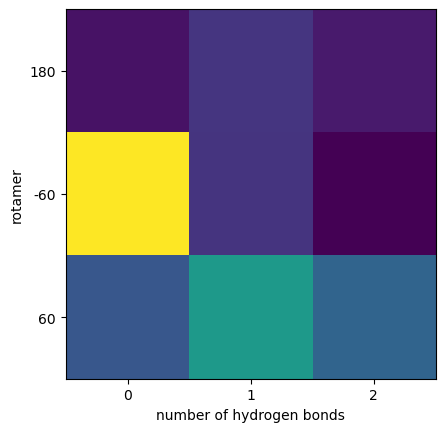

In [42]:
display_data = helix_rotamer_hbonds[0]
plt.imshow(display_data)
print(display_data)
plt.ylabel("rotamer")
plt.xlabel("number of hydrogen bonds")
plt.yticks([0,1,2],[180, -60, 60])
plt.xticks([0,1,2],[0,1,2])


[[  56.   69.   19.]
 [1600.  756.   23.]
 [ 537. 1083.   26.]]


([<matplotlib.axis.XTick at 0x77b82bcdca10>,
 [Text(0, 0, '0'), Text(1, 0, '1'), Text(2, 0, '2')])

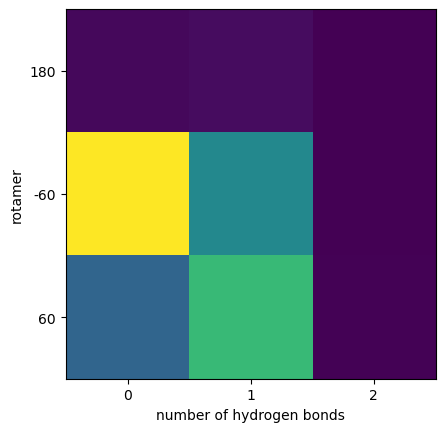

In [43]:
display_data = helix_rotamer_hbonds[1]
plt.imshow(display_data)
print(display_data)
plt.ylabel("rotamer")
plt.xlabel("number of hydrogen bonds")
plt.yticks([0,1,2],[180, -60, 60])
plt.xticks([0,1,2],[0,1,2])